# 24 · Pilot first, then pick or pair (post hoc)

**Status: post hoc, exploratory; follows notebook 23.** Reads only frozen prediction files and writes aggregates only.

**Rule.** A programme tests its two candidate systems on a local pilot: k cases with the target disease and k without, drawn from whole patients. It then compares their AUCs with a paired DeLong test. **If the pilot shows a clear difference (two-sided p < 0.05), it uses the stronger system alone; otherwise it runs both as a pair** at the same referral share. The threshold is fixed in advance from convention rather than tuned on these data; 0.01 and 0.20 are shown as sensitivity analyses.

**Comparators**, all scored on the images left after removing every image of the pilot patients:
- always pick the pilot winner (notebook 23 pilot rows);
- always pair (notebook 23 pair rows);
- the adaptive rule;
- a threshold on the raw AUC difference instead of a test, with the threshold chosen on the *other* populations and applied to this one (leave one population out);
- a hindsight bound: for each pair and draw, whichever of pick or pair did better.

The pilot draws use the same random sequence as notebook 23, so the always-pick and always-pair rows reproduce notebook 23 exactly. Regret is missed cases per 10,000 images above the better member; lower is better; negative means better than knowing in advance which system is stronger.

**Runtime:** CPU, about 30 minutes.

In [1]:
from google.colab import drive
drive.mount("/content/drive")
import os, re, json, hashlib, itertools, datetime, time, warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score
from scipy.stats import norm as _norm
DATA = "/content/drive/MyDrive/stochastic_orthogonality/data"
BASE = f"{DATA}/dr_ensemble_v2"; PREDS, SPLITS = f"{BASE}/03_predictions", f"{BASE}/01_splits"
BRSET_LABELS = f"{DATA}/brset/label_brset.csv"; DERM = f"{DATA}/derm"
OUTD = f"{BASE}/04_results/revisions_c1"; os.makedirs(OUTD, exist_ok=True)
OUT_JSON = f"{OUTD}/adaptive_rule_c1.json"
assert not os.path.exists(OUT_JSON), "already written; rename the old output deliberately to rerun"
SEED, DRAWS, KPILOT = 20261030, 100, (25, 50, 100)
ALPHAS = (0.01, 0.05, 0.20); ALPHA_MAIN = 0.05
TAUS = np.round(np.r_[0, np.arange(0.005, 0.1001, 0.005), 0.125, 0.15, 0.2, 0.3, 1.01], 3)   # 0 = always pick, 1.01 = always pair
def sha(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()
def refer(s, f):
    r = np.zeros(len(s), bool); r[np.argsort(-s, kind="stable")[:int(round(f * len(s)))]] = True; return r
def rk(s): return rankdata(s) / len(s)
def pairscore(ra, rb): return np.maximum(ra, rb) + 1e-9 * np.minimum(ra, rb)
def boot_w(groups, n_boot, seed):
    codes = pd.factorize(groups)[0]; G = codes.max() + 1; rng = np.random.default_rng(seed)
    W = np.empty((n_boot + 1, len(codes)), np.float32); W[0] = 1.0
    for b in range(1, n_boot + 1): W[b] = np.bincount(rng.integers(0, G, G), minlength=G)[codes]
    return W
def ci(x):
    x = np.asarray(x, float); f = x[1:][np.isfinite(x[1:])]
    return [float(x[0]), float(np.percentile(f, 2.5)), float(np.percentile(f, 97.5))]
def ci_basic(x):
    x = np.asarray(x, float); f = x[1:][np.isfinite(x[1:])]
    return [float(x[0]), float(2 * x[0] - np.percentile(f, 97.5)), float(2 * x[0] - np.percentile(f, 2.5))]
def pct(x): x = np.asarray(x, float); return [float(np.mean(x)), float(np.percentile(x, 2.5)), float(np.percentile(x, 97.5))]
def fmt(t, d=2): return f"{t[0]:.{d}f} ({t[1]:.{d}f} to {t[2]:.{d}f})"
def pick(cols, pats, what):
    m = [c for c in cols if any(re.fullmatch(p, c, flags=re.I) for p in pats)]
    assert len(m) == 1, f"cannot identify the {what} column; columns are {list(cols)}"
    return m[0]
def norm(x): return pd.Series(x, dtype=str).str.replace(r"\.(jpe?g|png|tiff?)$", "", regex=True, flags=re.I).to_numpy()
HASHES = {}
print("ready")

Mounted at /content/drive
ready


## 1. Load frozen predictions

In [2]:
ARCHS = ["densenet121_binary", "densenet121_5class", "efficientnet_b3_binary", "efficientnet_b3_5class", "resnet50_binary", "resnet50_5class",
         "vit_base_binary", "vit_base_5class", "retfound_binary", "retfound_5class", "retfound_adversarial"]
CORE4 = ["densenet121_5class", "efficientnet_b3_5class", "resnet50_5class", "retfound_5class"]
RSEEDS = [0, 1, 2]; RMODELS = [(a, k) for a in ARCHS for k in RSEEDS]
def tag(k): return "" if k == 0 else f"_seed{k}"
def load_preds(fmt_):
    P = {}; ref = None
    for a, k in RMODELS:
        fn = f"{PREDS}/{fmt_.format(arch=a, tag=tag(k))}"; HASHES[os.path.basename(fn)] = sha(fn)
        d = pd.read_csv(fn, dtype={"image_id": str})
        if ref is None: ref = d
        else: assert (d.image_id.values == ref.image_id.values).all(), fn
        P[(a, k)] = d["predicted_probability"].to_numpy(np.float64)
    return ref, P
RET = {}
ref, P = load_preds("eyepacs_predictions_fresh_{arch}{tag}_v2.csv")
RET["EyePACS"] = {"grade": ref.true_grade.to_numpy(int), "group": ref.patient_id.astype(str).to_numpy(), "P": P, "f": 0.25}
ref, P = load_preds("ddr_predictions_{arch}{tag}_v2.csv")
sp = pd.read_csv(f"{SPLITS}/ddr_split_intraset_v2.csv", dtype={"image_id": str})
gcol, grpcol = pick(sp.columns, ["grade", "true_grade", "dr_grade", "level"], "DDR grade"), pick(sp.columns, ["group", "filename_group", "group_id"], "DDR group")
sp["_k"] = norm(sp["image_id"]); sp = sp.set_index("_k").loc[norm(ref.image_id)]
g = sp[gcol].to_numpy(int); keep = g <= 4; isA = sp["half"].astype(str).str.upper().eq("A").to_numpy() if "half" in sp.columns else np.ones(len(g), bool)
RET["DDR"] = {"grade": g[keep], "group": sp[grpcol].astype(str).to_numpy()[keep], "P": {m: v[keep] for m, v in P.items()}, "f": round(1.31 * float((g[keep & isA] >= 2).mean()), 4)}
ref, P = load_preds("brset_predictions_eyepacs_{arch}{tag}_v2.csv")
lb = pd.read_csv(BRSET_LABELS, dtype=str)
icol, pcol, idcol = pick(lb.columns, [r".*icdr.*"], "BRSET ICDR grade"), pick(lb.columns, ["patient_id", "patient"], "BRSET patient"), pick(lb.columns, ["image_id", "image"], "BRSET image id")
lb["_k"] = norm(lb[idcol]); lb = lb.set_index("_k").loc[norm(ref.image_id)]
g = pd.to_numeric(lb[icol], errors="coerce").to_numpy(); keep = np.isin(g, [0, 1, 2, 3, 4])
RET["BRSET"] = {"grade": g[keep].astype(int), "group": lb[pcol].astype(str).to_numpy()[keep], "P": {m: v[keep] for m, v in P.items()}}
RET["BRSET"]["f"] = round(1.31 * float((RET["BRSET"]["grade"] >= 2).mean()), 4)
PB = {}
for src in ("eyepacs", "ddr"):
    for a in CORE4:
        for k in RSEEDS:
            fn = f"{PREDS}/brset_predictions_{src}_{a}{tag(k)}_v2.csv"; HASHES[os.path.basename(fn)] = sha(fn)
            d = pd.read_csv(fn, dtype={"image_id": str}); assert (norm(d.image_id) == lb.index.to_numpy()).all(), fn
            PB[(src, a, k)] = d["predicted_probability"].to_numpy(np.float64)[keep]
for n_, d in RET.items(): print(f"{n_:>8}: {len(d['grade']):,} images | {len(set(d['group'])):,} groups | f = {d['f']}")
# skin
CLASSES = ["MEL", "BCC", "SCC", "AK", "NV", "BKL", "DF", "VASC"]; SARCHS = ["resnet50", "densenet121", "efficientnet_b3", "convnext_t", "vit_b", "vit_b_dinov2"]
SOURCES = ["HAM10000", "BCN20000"]; SMODELS = [(s, a, k) for s in SOURCES for a in SARCHS for k in (0, 1)]; VARIANTS = [(s, a) for s in SOURCES for a in SARCHS]
SKIN = {}
for es in ("HIBA", "PAD"):
    D = pd.read_csv(f"{DERM}/manifest_{es}.csv", dtype={"image_id": str, "patient_id": str}).sort_values("image_id")
    D = D[~D.duplicated("raw_sha256", keep="first") & D.dx.isin(CLASSES)].reset_index(drop=True); P = {}
    for m in SMODELS:
        fn = f"{DERM}/predictions/{es}__{m[0]}_{m[1]}_seed{m[2]}.csv"; HASHES[os.path.basename(fn)] = sha(fn)
        p = pd.read_csv(fn, dtype={"image_id": str}).drop_duplicates("image_id").set_index("image_id").reindex(D.image_id); assert p.p_malignant.notna().all(); P[m] = p.p_malignant.to_numpy()
    dx = D.dx.to_numpy(); mal = np.isin(dx, ["MEL", "BCC", "SCC"])
    SKIN[es] = {"dx": dx, "mal": mal, "mel": dx == "MEL", "group": D.patient_id.astype(str).fillna("none").to_numpy(), "P": P, "f": round(1.31 * float(mal.mean()), 4)}
    print(f"{es:>8}: {len(dx):,} images | {len(set(SKIN[es]['group'])):,} patients | f = {SKIN[es]['f']}")

 EyePACS: 15,794 images | 7,897 groups | f = 0.25
     DDR: 12,422 images | 332 groups | f = 0.555
   BRSET: 16,266 images | 8,524 groups | f = 0.0745
    HIBA: 1,616 images | 623 patients | f = 0.6088
     PAD: 2,283 images | 1,373 patients | f = 0.6203


## 2. Rosters

In [3]:
def mname(m): return "_".join(str(x) for x in m)
ROSTERS = []
main_pairs = [((a, i), (b, j), "main roster") for a, b in itertools.combinations(ARCHS, 2) for i in RSEEDS for j in RSEEDS]
for pop in ("EyePACS", "DDR", "BRSET"):
    d = RET[pop]
    ROSTERS.append({"key": f"{pop}_severe", "label": f"{pop}, severe DR", "y": d["grade"] >= 3, "group": d["group"], "P": d["P"], "pairs": main_pairs, "f": d["f"]})
ROSTERS.append({"key": "DDR_pdr", "label": "DDR, PDR", "y": RET["DDR"]["grade"] == 4, "group": RET["DDR"]["group"], "P": RET["DDR"]["P"], "pairs": main_pairs, "f": RET["DDR"]["f"]})
def src_type(a, b):
    if a[0] == b[0]: return f"both {'EyePACS' if a[0] == 'eyepacs' else 'DDR'}-trained"
    return "one of each"
mixed_pairs = [(a, b, src_type(a, b)) for a, b in itertools.combinations(PB, 2) if a[:2] != b[:2]]
ROSTERS.append({"key": "BRSET_mixed_severe", "label": "BRSET, mixed training sources, severe DR", "y": RET["BRSET"]["grade"] >= 3, "group": RET["BRSET"]["group"], "P": PB, "pairs": mixed_pairs, "f": RET["BRSET"]["f"]})
skin_pairs = [((*va, i), (*vb, j), "same collection" if va[0] == vb[0] else "different collection") for va, vb in itertools.combinations(VARIANTS, 2) for i in (0, 1) for j in (0, 1)]
for es in ("HIBA", "PAD"):
    S = SKIN[es]
    for oname, y in (("melanoma", S["mel"]), ("any skin cancer", S["mal"])):
        ROSTERS.append({"key": f"{es}_{'mel' if oname == 'melanoma' else 'mal'}", "label": f"{es}, {oname}", "y": y, "group": S["group"], "P": S["P"], "pairs": skin_pairs, "f": S["f"]})
for R_ in ROSTERS: print(f"{R_['key']:22s} pairs {len(R_['pairs']):4d} | cases {int(R_['y'].sum()):5d} | f {R_['f']}")

EyePACS_severe         pairs  495 | cases   712 | f 0.25
DDR_severe             pairs  495 | cases  1149 | f 0.555
BRSET_severe           pairs  495 | cases   474 | f 0.0745
DDR_pdr                pairs  495 | cases   913 | f 0.555
BRSET_mixed_severe     pairs  252 | cases   474 | f 0.0745
HIBA_mel               pairs  264 | cases   253 | f 0.6088
HIBA_mal               pairs  264 | cases   751 | f 0.6088
PAD_mel                pairs  264 | cases    52 | f 0.6203
PAD_mal                pairs  264 | cases  1081 | f 0.6203


## 3. Pilot draws, the paired DeLong test, and the rules
For each draw, every system's DeLong structural components are computed on the pilot sample, so each pair's AUC difference has a variance that accounts for both systems being scored on the same cases.

In [4]:
def delong_parts(scores, ycal):
    """structural components for each model: V10 (positives) and V01 (negatives)"""
    pos, neg = ycal == 1, ycal == 0; V10, V01, A = {}, {}, {}
    for m, s in scores.items():
        X, Yn = s[pos][:, None], s[neg][None, :]; psi = (X > Yn) + 0.5 * (X == Yn)
        V10[m], V01[m] = psi.mean(1), psi.mean(0); A[m] = float(V10[m].mean())
    return A, V10, V01
def delong_p(a, b, V10, V01):
    d10, d01 = V10[a] - V10[b], V01[a] - V01[b]
    var = d10.var(ddof=1) / len(d10) + d01.var(ddof=1) / len(d01)
    diff = d10.mean()
    if var <= 0: return 1.0 if diff == 0 else 0.0
    return float(2 * _norm.sf(abs(diff) / np.sqrt(var)))
def eval_set(R_, ev):
    y, P, f = R_["y"][ev], R_["P"], R_["f"]; used = sorted({m for a, b, _ in R_["pairs"] for m in (a, b)}, key=str)
    K = {m: rk(P[m][ev]) for m in used}; M = {m: int((y & ~refer(P[m][ev], f)).sum()) for m in used}
    PM = {(a, b): int((y & ~refer(pairscore(K[a], K[b]), f)).sum()) for a, b, _ in R_["pairs"]}
    return M, PM, ev.sum()
POPS = {R_["key"]: R_["key"].split("_")[0] for R_ in ROSTERS}
DRAW = {}          # key -> k -> dict of arrays (draws x pairs)
for R_ in ROSTERS:
    t0 = time.time(); y = R_["y"]; pid = pd.factorize(R_["group"])[0]; npat = pid.max() + 1; P = R_["P"]
    used = sorted({m for a, b, _ in R_["pairs"] for m in (a, b)}, key=str)
    tpat = np.unique(pid[y]); opat = np.setdiff1d(np.arange(npat), tpat); rng = np.random.default_rng(SEED + 1); DRAW[R_["key"]] = {}
    types = np.array([t for _, _, t in R_["pairs"]])
    for k in KPILOT:
        if y.sum() < 2 * k: continue
        arr = {x: np.zeros((DRAWS, len(R_["pairs"]))) for x in ("pick", "pair", "absdiff", "p")}
        for dr in range(DRAWS):
            cs, ni = [], 0
            for p_ in rng.permutation(tpat):
                cs.append(p_); ni += int((y & (pid == p_)).sum())
                if ni >= k: break
            cn, nj = [], 0
            for p_ in rng.permutation(opat):
                cn.append(p_); nj += int((pid == p_).sum())
                if nj >= k: break
            si = rng.permutation(np.flatnonzero(y & np.isin(pid, cs)))[:k]; ni_ = rng.permutation(np.flatnonzero(np.isin(pid, cn)))[:k]
            cal = np.r_[si, ni_]; ycal = np.r_[np.ones(len(si)), np.zeros(len(ni_))]
            A, V10, V01 = delong_parts({m: P[m][cal] for m in used}, ycal)
            ev = ~np.isin(pid, np.r_[cs, cn]); M, PM, n = eval_set(R_, ev)
            for j, (a, b, _) in enumerate(R_["pairs"]):
                lo = min(M[a], M[b]); c = np.sign(A[a] - A[b]); ch = M[a] if c > 0 else (M[b] if c < 0 else 0.5 * (M[a] + M[b]))
                arr["pick"][dr, j] = (ch - lo) / n * 1e4; arr["pair"][dr, j] = (PM[(a, b)] - lo) / n * 1e4
                arr["absdiff"][dr, j] = abs(A[a] - A[b]); arr["p"][dr, j] = delong_p(a, b, V10, V01)
        arr["types"] = types; DRAW[R_["key"]][k] = arr
    print(f"{R_['key']:22s} done ({time.time() - t0:.0f}s)")

EyePACS_severe         done (355s)
DDR_severe             done (273s)
BRSET_severe           done (365s)
DDR_pdr                done (269s)
BRSET_mixed_severe     done (194s)
HIBA_mel               done (33s)
HIBA_mal               done (32s)
PAD_mel                done (13s)
PAD_mal                done (38s)


## 4. Results
For each roster and pilot size: mean regret over pairs, with the 2.5th and 97.5th percentiles across draws. "Share paired" is how often the adaptive rule chose to run both. The leave-one-population-out threshold is the raw AUC difference that minimised mean regret, averaged with equal weight over the rosters of the other populations at the same pilot size.

In [5]:
def summ(x): x = np.asarray(x).mean(1); return pct(x)
def tau_curve(arr):
    return np.array([np.where(arr["absdiff"] > t, arr["pick"], arr["pair"]).mean() for t in TAUS])
RES = {}
for key, byk in DRAW.items():
    RES[key] = {"label": next(R_["label"] for R_ in ROSTERS if R_["key"] == key)}
    for k, arr in byk.items():
        o = {"always_pick": summ(arr["pick"]), "always_pair": summ(arr["pair"]), "hindsight_best_of_pick_or_pair": summ(np.minimum(arr["pick"], arr["pair"]))}
        for al in ALPHAS:
            use_pick = arr["p"] < al
            o[f"adaptive_delong_alpha_{al}"] = summ(np.where(use_pick, arr["pick"], arr["pair"])); o[f"share_paired_alpha_{al}"] = float(1 - use_pick.mean())
        others = [kk for kk in DRAW if POPS[kk] != POPS[key] and k in DRAW[kk]]
        if others:
            curve = np.mean([tau_curve(DRAW[kk][k]) for kk in others], 0); t_ = float(TAUS[int(np.argmin(curve))])
            o["loo_tau"] = t_; o["adaptive_loo_tau"] = summ(np.where(arr["absdiff"] > t_, arr["pick"], arr["pair"])); o["share_paired_loo_tau"] = float((arr["absdiff"] <= t_).mean())
        o["tau_curve_this_population"] = tau_curve(arr).tolist()
        tl = {}
        for t in np.unique(arr["types"]):
            m_ = arr["types"] == t; use_pick = arr["p"][:, m_] < ALPHA_MAIN
            tl[str(t)] = {"always_pick": summ(arr["pick"][:, m_]), "always_pair": summ(arr["pair"][:, m_]), "adaptive": summ(np.where(use_pick, arr["pick"][:, m_], arr["pair"][:, m_])), "share_paired": float(1 - use_pick.mean())}
        o["by_pair_type"] = tl; RES[key][k] = o
        best = min(("always_pick", "always_pair", f"adaptive_delong_alpha_{ALPHA_MAIN}"), key=lambda s: o[s][0])
        print(f"{key:22s} k={k:3d} | pick {fmt(o['always_pick'])} | pair {fmt(o['always_pair'])} | adaptive {fmt(o[f'adaptive_delong_alpha_{ALPHA_MAIN}'])} (paired {o[f'share_paired_alpha_{ALPHA_MAIN}']:.0%})"
              + (f" | LOO tau {o['loo_tau']:.3f}: {fmt(o['adaptive_loo_tau'])}" if "loo_tau" in o else "") + f" | hindsight {fmt(o['hindsight_best_of_pick_or_pair'])} | best of three: {best}")
        if len(tl) > 1:
            for t, v in tl.items(): print(f"      {t:22s} pick {fmt(v['always_pick'])} | pair {fmt(v['always_pair'])} | adaptive {fmt(v['adaptive'])} (paired {v['share_paired']:.0%})")

EyePACS_severe         k= 25 | pick 2.92 (0.83 to 6.07) | pair -2.91 (-3.07 to -2.68) | adaptive -2.79 (-3.05 to -2.14) (paired 98%) | LOO tau 0.200: -2.91 (-3.07 to -2.68) | hindsight -3.07 (-3.28 to -2.77) | best of three: always_pair
EyePACS_severe         k= 50 | pick 2.31 (0.67 to 5.67) | pair -2.84 (-3.09 to -2.47) | adaptive -2.61 (-2.97 to -2.11) (paired 93%) | LOO tau 0.150: -2.84 (-3.09 to -2.47) | hindsight -3.01 (-3.28 to -2.61) | best of three: always_pair
EyePACS_severe         k=100 | pick 1.61 (0.45 to 4.10) | pair -2.63 (-2.99 to -2.11) | adaptive -2.32 (-2.80 to -1.69) (paired 88%) | LOO tau 0.090: -2.63 (-2.99 to -2.11) | hindsight -2.81 (-3.16 to -2.29) | best of three: always_pair
DDR_severe             k= 25 | pick 5.11 (1.60 to 9.95) | pair -3.55 (-3.82 to -3.11) | adaptive -3.04 (-3.73 to 0.02) (paired 93%) | LOO tau 0.200: -3.54 (-3.82 to -3.11) | hindsight -3.84 (-4.12 to -3.40) | best of three: always_pair
DDR_severe             k= 50 | pick 4.38 (1.44 to 9.2

## 5. Figure
Mean regret by pilot size for the three usable strategies, with the hindsight bound dashed. Lower is better; zero is the better member chosen with hindsight. Bands are the 2.5th to 97.5th percentiles across pilot draws.

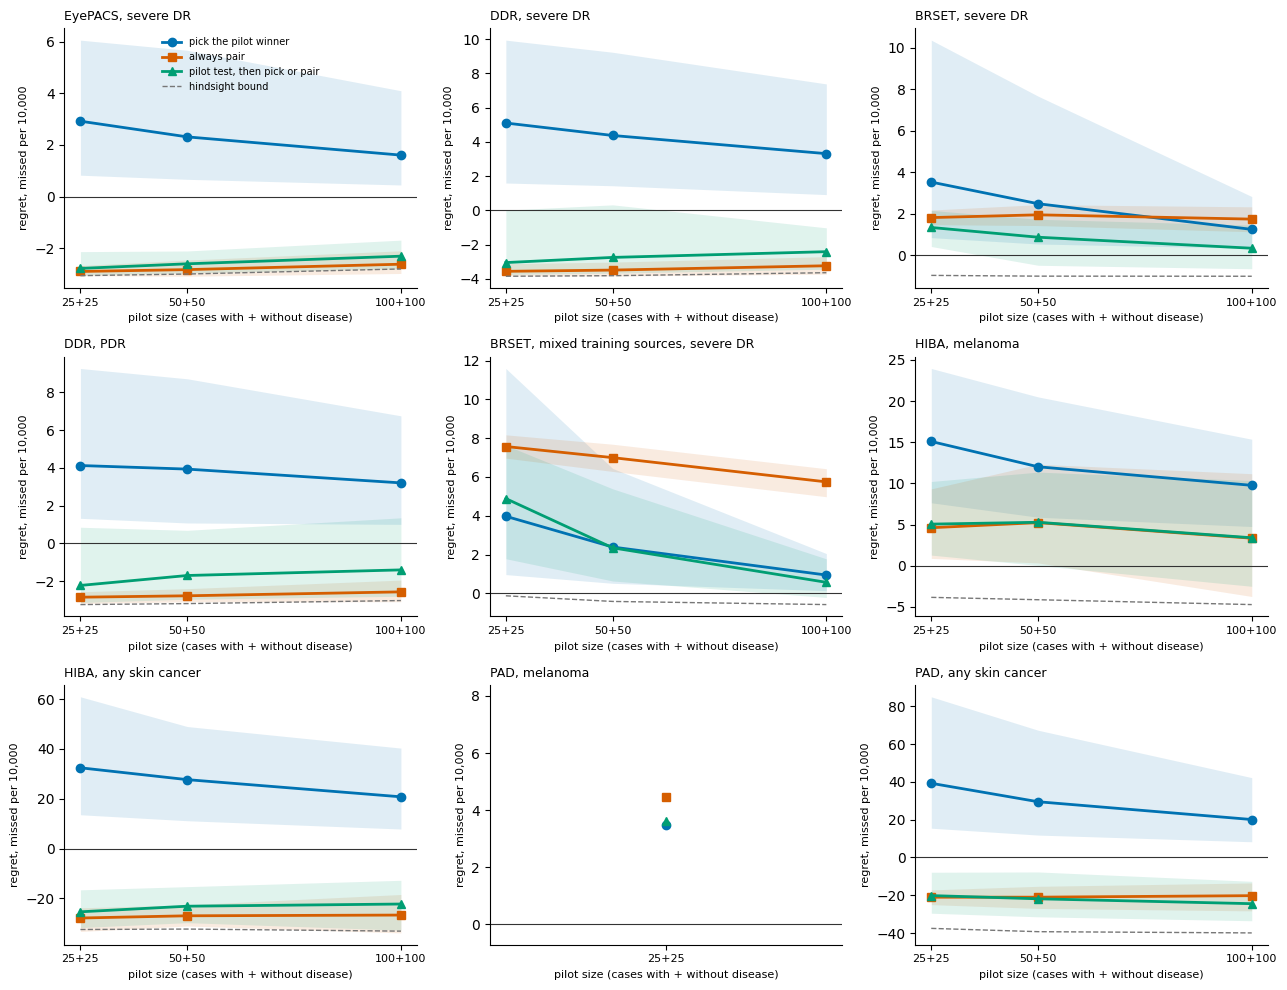

In [6]:
PANELS = [R_["key"] for R_ in ROSTERS]
STRAT = [("always_pick", "pick the pilot winner", "#0072B2", "o", "-"), ("always_pair", "always pair", "#D55E00", "s", "-"),
         (f"adaptive_delong_alpha_{ALPHA_MAIN}", "pilot test, then pick or pair", "#009E73", "^", "-"), ("hindsight_best_of_pick_or_pair", "hindsight bound", "#777777", None, "--")]
fig, ax = plt.subplots(3, 3, figsize=(13, 10))
for x_, key in zip(ax.flat, PANELS):
    ks = [k for k in KPILOT if k in RES[key]]
    for s, lab, col, mk, ls in STRAT:
        m = np.array([RES[key][k][s] for k in ks])
        x_.plot(ks, m[:, 0], color=col, marker=mk, ls=ls, lw=2 if mk else 1, ms=6, label=lab)
        if mk: x_.fill_between(ks, m[:, 1], m[:, 2], color=col, alpha=0.12, lw=0)
    x_.axhline(0, color="#333", lw=0.8); x_.set_xticks(ks); x_.set_xticklabels([f"{k}+{k}" for k in ks], fontsize=8)
    x_.set_title(RES[key]["label"], loc="left", fontsize=9); x_.set_xlabel("pilot size (cases with + without disease)", fontsize=8); x_.set_ylabel("regret, missed per 10,000", fontsize=8)
    [x_.spines[s_].set_visible(False) for s_ in ("top", "right")]
ax.flat[0].legend(fontsize=7, frameon=False)
fig.tight_layout(); fig.savefig(f"{OUTD}/adaptive_rule_c1.png", dpi=200); plt.show()

## Write the results record

In [7]:
REC = {"status": "post hoc, exploratory (review cycle 1 discussion); no lock", "written_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
       "rule": "pick the pilot AUC winner if paired DeLong p < alpha, otherwise pair; alpha 0.05 main, 0.01 and 0.20 sensitivity",
       "pilot_draws": DRAWS, "taus": TAUS.tolist(), "results": RES, "input_sha256": HASHES}
def tolist(x): return {str(k): tolist(v) for k, v in x.items()} if isinstance(x, dict) else ([tolist(v) for v in x] if isinstance(x, (list, tuple)) else (x.tolist() if isinstance(x, np.ndarray) else x))
with open(OUT_JSON, "w") as fh: json.dump(tolist(REC), fh, indent=1, default=float)
drive.flush_and_unmount(); drive.mount("/content/drive"); print("written", OUT_JSON)

Mounted at /content/drive
written /content/drive/MyDrive/stochastic_orthogonality/data/dr_ensemble_v2/04_results/revisions_c1/adaptive_rule_c1.json
